In [2]:
import copy
import sys
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'src' / 'py' / 'fpga_targets.py').is_file())
sys.path.insert(0, str(PROJECT_ROOT / 'src' / 'py'))

from data_model import build_model, prepare_mnist_dataset
from training import initialize_linear_layers, set_random_seed

save_dir = PROJECT_ROOT / 'data' / 'fashion'
save_dir.mkdir(parents=True, exist_ok=True)

train_raw = datasets.FashionMNIST(save_dir / 'raw', train=True, download=True)
test_raw = datasets.FashionMNIST(save_dir / 'raw', train=False, download=True)

# Aplatit les images 28x28 en 784 valeurs et ramène les pixels entre 0 et 1
train = prepare_mnist_dataset(train_raw.data.numpy(), train_raw.targets.numpy())
test = prepare_mnist_dataset(test_raw.data.numpy(), test_raw.targets.numpy())
print(train.x.shape, test.x.shape)  # (60000, 784) (10000, 784)


100%|██████████| 26.4M/26.4M [00:01<00:00, 19.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 867kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.03MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


(60000, 784) (10000, 784)


In [3]:
config = {
    'dataset_name': 'dataset_fashion.npz',
    'dataset_path': 'data/fashion/dataset_fashion.npz',
    'input_dim': 784,
    'layers': (64, 32),     # couches cachées uniquement
    'output_dim': 10,
    'activation': 'leaky_relu',
    'optimizer': 'AdamW',
    'init_weight': 'glorot_uniform',
    'learning_rate': 1e-3,
    'batch_size': 64,
    'epochs': 30,
    'patience': 5,
    'random_state': 7,
    'task': 'classification',
}

set_random_seed(config['random_state'])
indices = np.random.permutation(len(train.x))
val_idx, train_idx = indices[:6000], indices[6000:]

def make_loader(x, y, shuffle=False):
    tensors = TensorDataset(torch.from_numpy(x), torch.from_numpy(y))
    return DataLoader(tensors, batch_size=config['batch_size'], shuffle=shuffle)

train_loader = make_loader(train.x[train_idx], train.y[train_idx], shuffle=True)
val_loader = make_loader(train.x[val_idx], train.y[val_idx])
test_loader = make_loader(test.x, test.y)

model = build_model(config)
initialize_linear_layers(model, config['init_weight'])
optimizer = torch.optim.AdamW(model.parameters(), lr=config['learning_rate'])
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            logits = model(x)
            total_loss += criterion(logits, y).item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()
            total += len(y)
    return total_loss / total, correct / total


In [4]:
best_loss, best_state, wait = float('inf'), None, 0

for epoch in range(1, config['epochs'] + 1):
    model.train()
    for x, y in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    val_loss, val_acc = evaluate(model, val_loader)
    print(f'Epoch {epoch:2d} | val_loss={val_loss:.4f} | val_acc={val_acc:.2%}')

    if val_loss < best_loss:
        best_loss, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        wait += 1
        if wait >= config['patience']:
            print('Early stopping')
            break

model_path = save_dir / 'mlp_fashion.pt'
torch.save({'model_state_dict': best_state, 'config': config}, model_path)
np.savez(save_dir / 'dataset_fashion.npz',
         x_train=train.x, y_train=train.y, x_test=test.x, y_test=test.y)


Epoch  1 | val_loss=0.4406 | val_acc=84.10%
Epoch  2 | val_loss=0.3924 | val_acc=85.88%
Epoch  3 | val_loss=0.3774 | val_acc=87.10%
Epoch  4 | val_loss=0.3570 | val_acc=87.27%
Epoch  5 | val_loss=0.3430 | val_acc=87.42%
Epoch  6 | val_loss=0.3469 | val_acc=87.13%
Epoch  7 | val_loss=0.3419 | val_acc=87.47%
Epoch  8 | val_loss=0.3324 | val_acc=88.27%
Epoch  9 | val_loss=0.3324 | val_acc=87.57%
Epoch 10 | val_loss=0.3307 | val_acc=87.95%
Epoch 11 | val_loss=0.3474 | val_acc=87.47%
Epoch 12 | val_loss=0.3431 | val_acc=87.62%
Epoch 13 | val_loss=0.3181 | val_acc=88.38%
Epoch 14 | val_loss=0.3135 | val_acc=88.85%
Epoch 15 | val_loss=0.3257 | val_acc=88.55%
Epoch 16 | val_loss=0.3497 | val_acc=87.82%
Epoch 17 | val_loss=0.3240 | val_acc=88.48%
Epoch 18 | val_loss=0.3237 | val_acc=88.67%
Epoch 19 | val_loss=0.3198 | val_acc=88.58%
Early stopping


In [5]:
checkpoint = torch.load(model_path, weights_only=False)
reloaded = build_model(checkpoint['config'])
reloaded.load_state_dict(checkpoint['model_state_dict'])
reloaded.eval()

test_loss, test_acc = evaluate(reloaded, test_loader)
print(f'Test : loss={test_loss:.4f} | accuracy={test_acc:.2%}')

with torch.no_grad():
    predictions = reloaded(torch.from_numpy(test.x)).argmax(dim=1).numpy()

for class_id, name in enumerate(test_raw.classes):
    mask = test.y == class_id
    print(f'{name:15s}: {(predictions[mask] == class_id).mean():.2%}')


Test : loss=0.3423 | accuracy=88.17%
T-shirt/top    : 86.00%
Trouser        : 97.20%
Pullover       : 78.00%
Dress          : 88.60%
Coat           : 83.90%
Sandal         : 97.70%
Shirt          : 63.50%
Sneaker        : 95.10%
Bag            : 96.50%
Ankle boot     : 95.20%


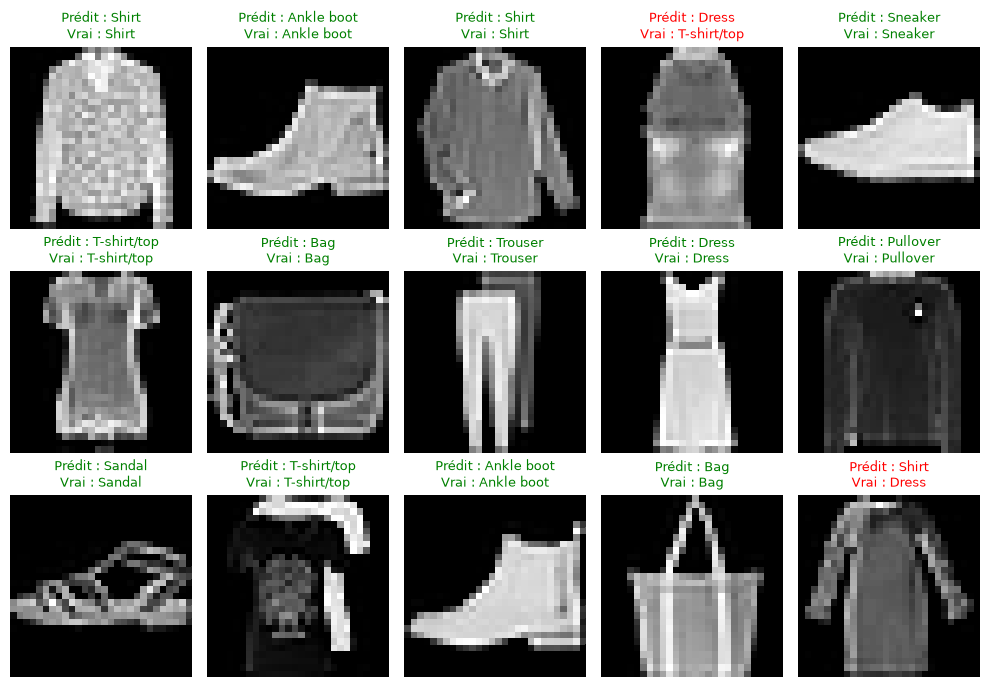

In [6]:
import matplotlib.pyplot as plt

samples = np.random.default_rng(0).choice(len(test.x), size=15, replace=False)

fig, axes = plt.subplots(3, 5, figsize=(10, 7))
for ax, i in zip(axes.flat, samples):
    ax.imshow(test.x[i].reshape(28, 28), cmap='gray')
    pred, true = test_raw.classes[predictions[i]], test_raw.classes[test.y[i]]
    ax.set_title(f'Prédit : {pred}\nVrai : {true}',
                 color='green' if pred == true else 'red', fontsize=9)
    ax.axis('off')
fig.tight_layout()
plt.show()
